In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

In [23]:
df = pd.read_csv('ecommerce_customer_data_custom_ratios.csv.zip')

In [24]:
# 3. Extract Date Features
df['Purchase Date'] = pd.to_datetime(
    df['Purchase Date'], errors='coerce'
)

df['Month'] = df['Purchase Date'].dt.month
df['Day'] = df['Purchase Date'].dt.dayofweek

df = df.drop(columns=['Purchase Date'])

In [25]:
# 4. Remove Unnecessary Columns
df = df.drop(
    columns=['Customer Name', 'Age', 'Churn'],
    errors='ignore'
)


In [26]:
# 5. Remove Missing Target Values
df = df.dropna(subset=['Returns'])

In [27]:
# 6. Separate Customer IDs for Customer-wise Splitting
customer_ids = df['Customer ID'].copy()
X = df.drop(columns=['Returns', 'Customer ID'])
y = df['Returns'].astype(int)

In [28]:
# 7. Split by Customer
train_ids, test_ids = train_test_split(
    customer_ids.drop_duplicates(),
    test_size=0.2,
    random_state=42
)

train_mask = customer_ids.isin(train_ids)
test_mask = customer_ids.isin(test_ids)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (161829, 9)
Testing Data: (40575, 9)


In [29]:
# 8. Identify Numerical and Categorical Columns
numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

In [30]:
# 9. Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [31]:
# 10. Define Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}


In [32]:
# 11. Train and Evaluate Models
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print("\n================================")
    print("MODEL:", name)
    print("================================")

    print("Accuracy:", round(accuracy, 4))
    print("ROC-AUC:", round(auc, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'ROC-AUC': auc
    })

    trained_models[name] = pipeline



MODEL: Logistic Regression
Accuracy: 0.5001
ROC-AUC: 0.4996

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.70      0.59     20360
           1       0.50      0.30      0.37     20215

    accuracy                           0.50     40575
   macro avg       0.50      0.50      0.48     40575
weighted avg       0.50      0.50      0.48     40575

Confusion Matrix:
[[14310  6050]
 [14232  5983]]

MODEL: Decision Tree
Accuracy: 0.4983
ROC-AUC: 0.4959

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.59      0.54     20360
           1       0.50      0.40      0.44     20215

    accuracy                           0.50     40575
   macro avg       0.50      0.50      0.49     40575
weighted avg       0.50      0.50      0.49     40575

Confusion Matrix:
[[12075  8285]
 [12072  8143]]

MODEL: Random Forest
Accuracy: 0.5009
ROC-AUC: 0.5

Classification Report:
        

In [33]:
# 12. Compare Model Performance
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.sort_values(by='ROC-AUC', ascending=False))



MODEL COMPARISON


,Model,Accuracy,ROC-AUC
2,Random Forest,0.500850,0.500011
0,Logistic Regression,0.500136,0.499649
1,Decision Tree,0.498287,0.495893


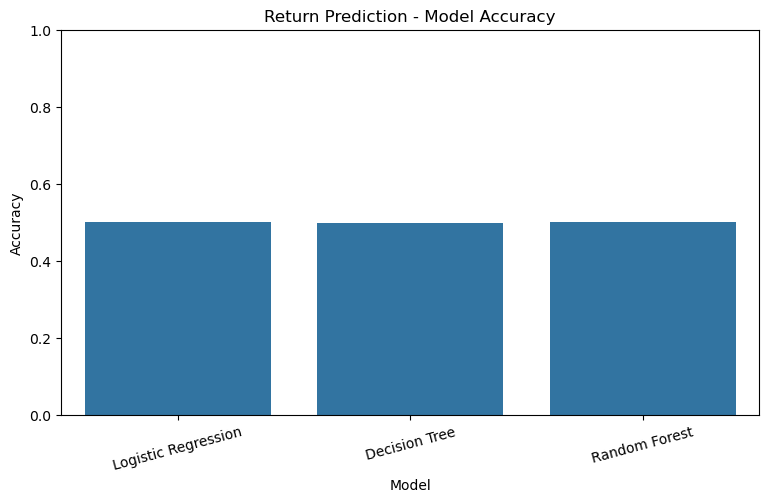

In [34]:
# 13. Visualize Accuracy
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.title('Return Prediction - Model Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

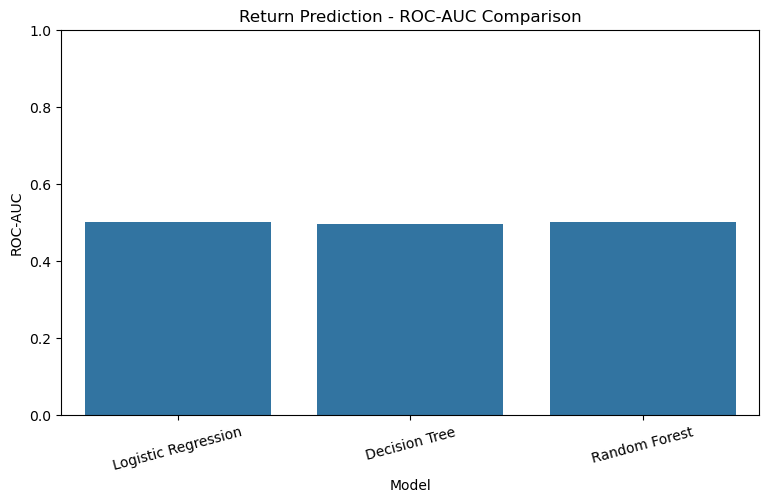

In [35]:
# 14. Visualize ROC-AUC
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='ROC-AUC')
plt.title('Return Prediction - ROC-AUC Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [36]:
# 15. Select Best Model
best_model_name = results_df.sort_values(
    by='ROC-AUC', ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)


Best Model: Random Forest


In [37]:
# 16. Save All Models and Best Model
os.makedirs('models', exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(' ', '_')
    joblib.dump(model, f'models/return_{filename}.pkl')

joblib.dump(best_model, 'models/return_model.pkl')

print("\nReturn Prediction Models Saved Successfully!")



Return Prediction Models Saved Successfully!
